# Лабораторная работа №5:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV, ElasticNetCV, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

**Мини-вывод:** Подключил библиотеки

In [2]:
df = pd.read_csv("2015.csv")
# На случай пропусков в числовых колонках заполняем их медианой
for col in df.select_dtypes(include="number").columns:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

# Убираем уникальное название страны, ранг счастья и остаток дистопии (чтобы не было прямой утечки формулы таргета)
df = df.drop(["Country", "Happiness Rank", "Dystopia Residual"], axis=1)
df = pd.get_dummies(df, drop_first=True)

X = df.drop("Happiness Score", axis=1)
y = df["Happiness Score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

corr_matrix = X.corr()

print("Матрица корреляций")
display(corr_matrix.round(2))

Матрица корреляций


,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Region_Central and Eastern Europe,Region_Eastern Asia,Region_Latin America and Caribbean,Region_Middle East and Northern Africa,Region_North America,Region_Southeastern Asia,Region_Southern Asia,Region_Sub-Saharan Africa,Region_Western Europe
Standard Error,1.00,-0.22,-0.12,-0.31,-0.13,-0.18,-0.09,-0.07,-0.12,0.31,-0.03,-0.07,-0.07,-0.20,0.25,-0.24
Economy (GDP per Capita),-0.22,1.00,0.65,0.82,0.37,0.31,-0.01,0.11,0.15,0.03,0.21,0.14,-0.03,-0.15,-0.67,0.44
Family,-0.12,0.65,1.00,0.53,0.44,0.21,0.09,0.11,0.08,0.17,-0.10,0.12,-0.05,-0.27,-0.39,0.37
Health (Life Expectancy),-0.31,0.82,0.53,1.00,0.36,0.25,0.11,0.17,0.20,0.12,0.12,0.12,0.05,-0.08,-0.82,0.44
Freedom,-0.13,0.37,0.44,0.36,1.00,0.49,0.37,-0.22,0.04,0.20,-0.17,0.12,0.21,-0.08,-0.24,0.32
Trust (Government Corruption),-0.18,0.31,0.21,0.25,0.49,1.00,0.28,-0.22,-0.03,-0.09,0.12,0.10,0.02,-0.07,-0.10,0.29
Generosity,-0.09,-0.01,0.09,0.11,0.37,0.28,1.00,-0.32,-0.02,-0.06,-0.14,0.17,0.35,0.18,-0.07,0.20
Region_Central and Eastern Europe,-0.07,0.11,0.11,0.17,-0.22,-0.22,-0.32,1.00,-0.09,-0.19,-0.18,-0.05,-0.12,-0.10,-0.28,-0.19
Region_Eastern Asia,-0.12,0.15,0.08,0.20,0.04,-0.03,-0.02,-0.09,1.00,-0.08,-0.08,-0.02,-0.05,-0.04,-0.12,-0.08
Region_Latin America and Caribbean,0.31,0.03,0.17,0.12,0.20,-0.09,-0.06,-0.19,-0.08,1.00,-0.15,-0.05,-0.10,-0.09,-0.23,-0.16


**Мини-вывод:** В таблице 16 признаков. Видно, что экономика и здоровье сильно связаны (`0.82`), а у Африки сильный минус со здоровьем (`-0.82`) и экономикой (`-0.67`).

In [3]:
lr = LinearRegression()
lr.fit(X_train, y_train)

alphas_to_test = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0, 100.0]
ridge_cv = RidgeCV(alphas=alphas_to_test)
ridge_cv.fit(X_train, y_train)

lasso_cv = LassoCV(alphas=alphas_to_test, random_state=42)
lasso_cv.fit(X_train, y_train)
lasso = Lasso(alpha=0.2, random_state=42)
lasso.fit(X_train, y_train)
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]
elastic_cv = ElasticNetCV(l1_ratio=l1_ratios, alphas=alphas_to_test, cv=5, random_state=42)
elastic_cv.fit(X_train, y_train)

print(f"alpha l2 = {ridge_cv.alpha_}")
print(f"alpha l1 = {lasso_cv.alpha_}")
print(f"alpha l1/l2 = {elastic_cv.alpha_}")
print(f"Оптимальное соотношение L1/L2 (l1_ratio): {elastic_cv.l1_ratio_}")

print("Веса OLS")
print(np.round(lr.coef_, 3))
print("Веса Ridge (L2)")
print(np.round(ridge_cv.coef_, 3))
print("Веса Lasso (L1)")
print(np.round(lasso_cv.coef_, 3))
print("Веса Lasso (L1) (alpha = 0.2)")
print(np.round(lasso.coef_, 3))
print("Веса ElasticNet:")
print(np.round(elastic_cv.coef_, 3))

alpha l2 = 10.0
alpha l1 = 0.01
alpha l1/l2 = 0.1
Оптимальное соотношение L1/L2 (l1_ratio): 0.3
Веса OLS
[-0.06   0.398  0.302  0.132  0.127  0.098  0.07  -0.23  -0.148  0.058
 -0.154  0.019 -0.131 -0.117 -0.262 -0.08 ]
Веса Ridge (L2)
[-0.045  0.34   0.299  0.157  0.131  0.107  0.067 -0.078 -0.068  0.163
 -0.03   0.065 -0.045 -0.037 -0.116  0.056]
Веса Lasso (L1)
[-0.044  0.391  0.306  0.146  0.125  0.108  0.069 -0.028 -0.043  0.211
  0.     0.07  -0.008 -0.    -0.043  0.08 ]
Веса Lasso (L1) (alpha = 0.2)
[-0.     0.317  0.26   0.172  0.135  0.     0.    -0.    -0.     0.
 -0.     0.    -0.    -0.    -0.     0.   ]
Веса ElasticNet:
[-0.002  0.33   0.298  0.16   0.132  0.107  0.05  -0.014 -0.015  0.161
  0.     0.059 -0.    -0.    -0.059  0.085]


**Мини-вывод:** У обычной OLS самый большой разброс весов (до `0.398` и `-0.262`). Ridge и ElasticNet эти скачки сгладили, а жёсткий `Lasso (L1) (alpha = 0.2)` обнулил почти всё и оставил только 4 веса.

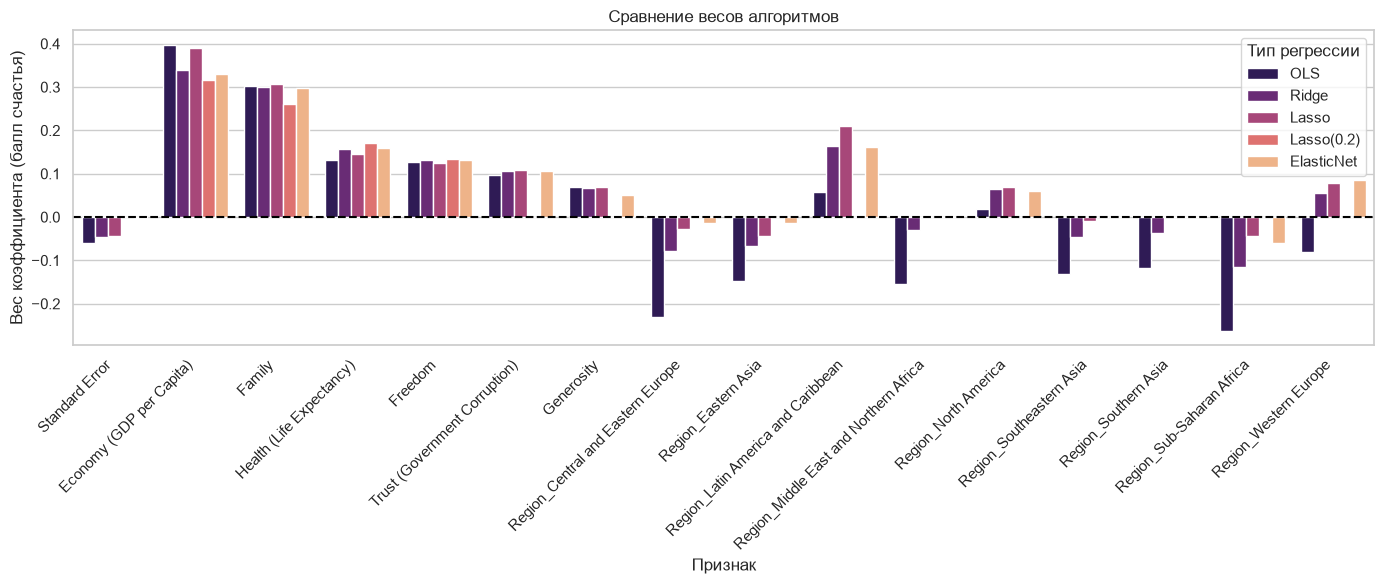

In [ ]:
weights_df = pd.DataFrame(
    {
        "Признак": X.columns,
        "OLS": lr.coef_,
        "Ridge": ridge_cv.coef_,
        "Lasso": lasso_cv.coef_,
        "Lasso(0.2)": lasso.coef_,
        "ElasticNet": elastic_cv.coef_
    }
)
weights_melted = weights_df.melt(
    id_vars="Признак", var_name="Модель", value_name="Влияние на индекс (Вес)"
)
plt.figure(figsize=(14, 6))
sns.barplot(
    data=weights_melted,
    x="Признак",
    y="Влияние на индекс (Вес)",
    hue="Модель",
    palette="magma"
)

plt.axhline(0, color="black", lw=1.5, ls="--")
plt.title("Сравнение весов алгоритмов")
plt.ylabel("Вес коэффициента (балл счастья)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Тип регрессии")
plt.tight_layout()
plt.show()

**Мини-вывод:** Главные плюсы дают экономика, семья, здоровье и свобода. У обычной модели сильно проседают в минус регионы, а Ridge и ElasticNet их подтягивают к нулю. У жёсткого `Lasso(0.2)` остались только 4 столбика, остальные в нуле.

In [5]:
print(f"R2 для OLS: {r2_score(y_test, lr.predict(X_test)):.4f}")
print(f"R2 для Ridge: {r2_score(y_test, ridge_cv.predict(X_test)):.4f}")
print(f"R2 для Lasso: {r2_score(y_test, lasso_cv.predict(X_test)):.4f}")
print(f"R2 для Lasso(0.2): {r2_score(y_test, lasso.predict(X_test)):.4f}")
print(f"R2 для ElasticNet: {r2_score(y_test, elastic_cv.predict(X_test)):.4f}")

R2 для OLS: 0.8551
R2 для Ridge: 0.8511
R2 для Lasso: 0.8534
R2 для Lasso(0.2): 0.7653
R2 для ElasticNet: 0.8496


**Мини-вывод:** У первых четырёх моделей точность почти одна и та же ($R^2 = 0.85$). У жёсткого `Lasso(0.2)` точность упала до `0.7653`, но зато осталось всего 4 признака вместо 16.

### Бизнес-вывод
* На счастье сильнее всего влияют экономика (`Economy`), семья (`Family`), здоровье (`Health`) и свобода (`Freedom`).
* Если нужна высокая точность - берём Ridge или ElasticNet ($R^2 = 0.8511$): веса ровные, качество не падает.
* Если важнее простота - берём `Lasso(0.2)`: теряем около 9% точности ($R^2 = 0.7653$), но модель держится всего на 4 понятных показателях.